# 06.01 ARTIFICIAL NEURAL NETWORKS - CLASSIFICATION - EXERCISES (SOLUTIONS)

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
import tensorflow as tf

# reproducibility
np.random.seed(0)
tf.random.set_seed(0)

In [2]:
# Helper function for plotting losses
def plot_loss(history):
    plt.plot(history.history['loss'])
    if 'val_loss' in history.history:
        plt.plot(history.history['val_loss'])
        plt.legend(['Train', 'Val'], loc='upper left')
    plt.title('Model loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.show()

## EXERCISE 1

A very small NN has an input layer with 2 nodes and an output layer with 1 node. The are no hidden nodes. Calculate the feedforward pass if the input is [1, 1] the weights are [0.3, -0.1] and the bias is -0.7. The activation function used by the output layer is `sigmoid`. Use numpy arrays and the python `math` module to calculate the output the integration and activation function of the output node. Which of the 2 inputs has the biggest influence one the output?

In [3]:
input = np.array([1, 1])
weights = np.array([0.3, -0.1])
bias = -0.7

#integration = 1 * 0.3 + 1 * (-0.1) - 0.7
integration = np.sum(input * weights) + bias

# Biggest influence: 1st

# activation = sigmoid
activation = 1 / (1 + math.exp(-integration))

print('integration:', integration)
print('activation (sigmoid):', activation)
# The first input (weight 0.3) has larger absolute influence than the second (-0.1).


integration: -0.5
activation (sigmoid): 0.3775406687981454


## EXERCISE 2

The goal is to predict the quality class of wine, based on features that come from a chemical analysis of the wine.

In [4]:
wine = load_wine()
wine_X = wine.data
wine_y = wine.target
print(wine.DESCR)

.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0
        - class_1
        - class_2

:Summary Statistics:

============================= ==== ===== ======= =====
                                Min   Max   Mean     SD
============================= ==== ===== ======= =====
Alcohol:                      11.0  14.8    13.0   0.8
Malic Acid:                   0.74  5.80    2.34  1.12
Ash:                          1.36  3.23    2.36  0.27
Alcalinity of Ash:            10.6  30.0    19.5   3.3
Magnesium:                    70.0 162.0    99.7  14.3

### 1. Data preparation

a. Print the shapes of wine_x and wine_y. How many wines do we have? How many featues do we have? Check whether there NaN values. How many quality classes do we have?

In [5]:
print('wine_X.shape:', wine_X.shape)
print('wine_y.shape:', wine_y.shape)

wine_X.shape: (178, 13)
wine_y.shape: (178,)


In [6]:
print('missing values in wine_X:', np.isnan(wine_X).sum())

missing values in wine_X: 0


In [7]:
print('unique classes:', np.unique(wine_y))

unique classes: [0 1 2]


b. Split the data in a train (85%) and test dataset (15%) (why do we do this?). Scale the train set using min_max scaling (why do we do this?). <strong>Important:</strong> We only fit scalers on training data and reuse the fitted scaler to scale test data. Put the output in the right format. What is the name of the format?

In [8]:
wine_X_train, wine_X_test, wine_y_train, wine_y_test = train_test_split(
    wine_X, wine_y, test_size=0.15, random_state=0
)

In [9]:
scaler = MinMaxScaler()
wine_scaler = MinMaxScaler()
wine_X_train_scaled = wine_scaler.fit_transform(wine_X_train)
wine_X_test_scaled = wine_scaler.transform(wine_X_test) # Only transform no fit!

In [10]:
# One-hot targets
wine_y_train_onehot = to_categorical(wine_y_train)
wine_y_test_onehot = to_categorical(wine_y_test)
print(wine_y_train_onehot.shape)
print(wine_y_train_onehot)

(151, 3)
[[0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 1.]
 [0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1.

### 2. Define the model

Define the input layer with the right number of nodes. For the hidden layers, try out several options yourself. Define the output layer with the right number of nodes and a correct activation function. Print a model summary and compile the model with the Adam optimizer (choose the learning rate yourself), the correct loss function and a well choosen metric.

In [11]:
# Model
n_features_wine = wine_X.shape[1] # Number of features
n_classes_wine = wine_y_train_onehot.shape[1] # Number of classes

# input layer 784 nodes
inputs = Input(shape=(n_features_wine,))
# 2 hidden layer
x = Dense(128, activation='relu')(inputs)
x = Dense(64, activation='relu')(x)
# output layer
outputs = Dense(n_classes_wine, activation='softmax')(x)
# construct the model
wine_model = Model(inputs, outputs, name='WINE')

# compile the model
wine_model.compile(optimizer=Adam(learning_rate=1e-3),
                   loss='categorical_crossentropy',
                   metrics=['accuracy'])
# print a summary
wine_model.summary()

Model: "WINE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 13)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,243 (40.01 KB)

 Trainable params: 10,243 (40.01 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Train the model

Train the model with 10% of the training data taken for validation. Choose the number of epochs and the batch_size. Plot the loss function. Do we have overfitting?

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.3926 - loss: 1.0757 - val_accuracy: 0.3750 - val_loss: 1.0381
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5333 - loss: 1.0011 - val_accuracy: 0.5625 - val_loss: 0.9681
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7926 - loss: 0.9362 - val_accuracy: 0.9375 - val_loss: 0.9027
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9407 - loss: 0.8734 - val_accuracy: 1.0000 - val_loss: 0.8331
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9481 - loss: 0.8064 - val_accuracy: 1.0000 - val_loss: 0.7603
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9407 - loss: 0.7367 - val_accuracy: 1.0000 - val_loss: 0.6890
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9556 - loss: 0.6661 - val_accuracy: 1.0000 - val_loss: 0.6202
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9556 - loss: 0.5972 - val_accuracy: 0.9375 - val_loss:

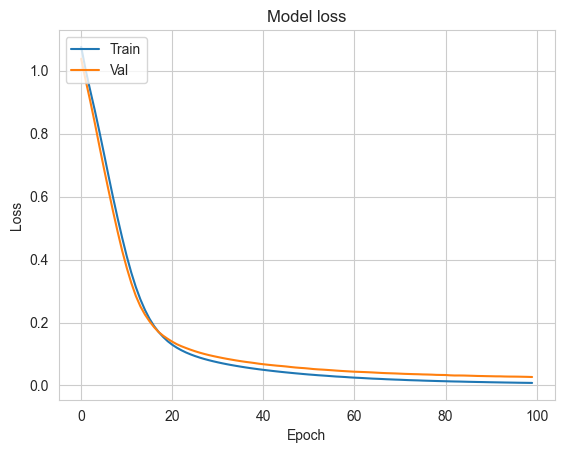

In [12]:
# train the model
history_wine = wine_model.fit(
    wine_X_train_scaled, # training input
    wine_y_train_onehot, # training targets
    epochs=100,
    batch_size=32,
    validation_split=0.1,
)
# plot loss function
plot_loss(history_wine)

### 4. Evaluate the model

Evaluate the model with the test dataset (why this one?). What is the accuracy of the model?

In [13]:
eval_results = wine_model.evaluate(wine_X_test_scaled, wine_y_test_onehot, verbose=0)# Scaled features, since the model was trained on scaled features as well!!
print('Wine test loss, accuracy:', eval_results)

Wine test loss, accuracy: [0.0062624807469546795, 1.0]


### 5. Use the model to predict

There is a new wine with the following characteristics for the features: 12, 6.5, 3, 25, 100, 2.5, 4, 0.5, 2, 8, 1, 3, 500. Predict the quality for this wine. What should be the shape of the predict variable? Can we feed in the feature values right away? Which quality class is predicted? How confident is the model of this prediction?

In [14]:
# Predict a new wine (scale before predict)
new_wine = np.array([[12, 6.5, 3, 25, 100, 2.5, 4, 0.5, 2, 8, 1, 3, 500]])
new_wine_scaled = wine_scaler.transform(new_wine)
probs = wine_model.predict(new_wine_scaled)
pred_class = int(np.argmax(probs, axis=1)[0])
confidence = float(probs[0, pred_class])
print('Confidence of each class:', probs,'Predicted class:', pred_class, 'confidence:', confidence) # The second quality class has the highest output/confidence score, meaning it will be the predicted class

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Confidence of each class: [[9.354293e-02 9.064506e-01 6.383697e-06]] Predicted class: 1 confidence: 0.906450629234314
